## Veriler Hakkında
Bu projede kullanılan veriler gerçektir ve 20 yılı aşkın bir süredir toplanan verilere dayanmaktadır.
Bu veri setindeki toplam kayıt sayısı yaklaşık 120 milyon satırdır ve veri boyutu
yaklaşık 12 GB'tır. Veriler
, Ekim 1987'den Nisan 2008'e kadar ABD içindeki tüm ticari uçuşların varış ve kalkış bilgilerini içermektedir. Bu büyük bir veri setidir.
Yaklaşık 29 özellik bulunmaktadır.

### Verilere nasıl ulaşılır?
Veriler orijinal olarak http://stat-computing.org/dataexpo/2009/the-data.html adresinden alınmıştır.

Yukarıdaki web sitesinde ilgili bağlantıya tıklayarak her yıla ait verileri indirebilirsiniz
(Dosya boyutunun 12 GB'tan fazla olacağını unutmayın).

### (i) Problem Bildirimi
(a) Havayollarının kat ettiği mesafenin çarpıklığını kontrol edin.
(b) ABD Havayollarının (US) kat ettiği mesafenin ortalamasını, medyanını ve kantillerini hesaplayın.
(c) American Airlines'ın (AA) kat ettiği mesafenin standart sapmasını kontrol edin.
(d) Mesafe ile Benzersiz Havayolu Şirketi arasındaki ilişkiyi gösteren bir kutu grafiği çizin.
(e) Bir saçılım grafiği çizerek Varış Gecikmesi ve Kalkış Gecikmesi arasındaki ilişkinin yönünü gösterin.

### (ii) Problem Bildirimi

(a) İniş/kalkış yapan bir uçuşun “WN” Havayolları'na ait olma olasılığı nedir (marjinal olasılık)?
(b) İniş/kalkış yapan bir uçuşun “WN” veya “AA” Havayolları'na ait olma olasılığı nedir (ayrık olaylar)?
(c) Bir uçuşun hem “WN” olması hem de 600 milden daha az mesafe kat etmesi olasılığı nedir (ortak olasılık)?
(d) Uçuşun “AA” Havayolları'na ait olduğu bilindiğinde, uçuşun 2500 milden daha az mesafe kat etmesi olasılığı nedir (koşullu olasılık)?
(e) Bir uçuşun “AA” Havayolları'na ait olduğu bilindiğinde, uçuşun iptal edilmesi ve 2500 milden daha az mesafe kat etmesi olasılığı nedir (ortak + koşullu olasılık)?

### (iii) Problem Bildirimi

(a) “AA” şirketine ait uçuşların varış gecikmelerinin ortalama 15 dakika ve standart sapma 3 dakika olan normal dağılıma sahip olduğunu varsayalım. “AA”, uçuşlarının 20 dakika gecikmesi durumunda %50 nakit iadesi yapacağı bir plan açıklarsa, “AA”nın bu parayı uçuşların yüzde kaçında kaybedeceği tahmin edilmektedir? (İpucu: pnorm)
(b) Uçuşların %65'inin kötü hava koşulları nedeniyle Hava Durumu Sistemi aracılığıyla yönlendirildiğini varsayalım. Rastgele seçilen 10 uçuştan 6'sının Hava Durumu Sistemi aracılığıyla yönlendirilme olasılığı nedir? (İpucu: dbinorm)
(c) Uçuşların Varış Gecikmesi ve Kalkış Gecikmesi arasında doğrusal regresyon yapın.
(d) Uyumlu doğrusal regresyon doğrusunun güven aralığını bulun.
(e) Varış Gecikmesi ve Kalkış Gecikmesi ile uçuşların kat ettiği mesafe arasında çoklu doğrusal regresyon yapın.

C:\Users\tatls\AppData\Local\Temp\ipykernel_35752\976528538.py:4: DtypeWarning: Columns (23) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("airline_dec_2008_50k.csv")


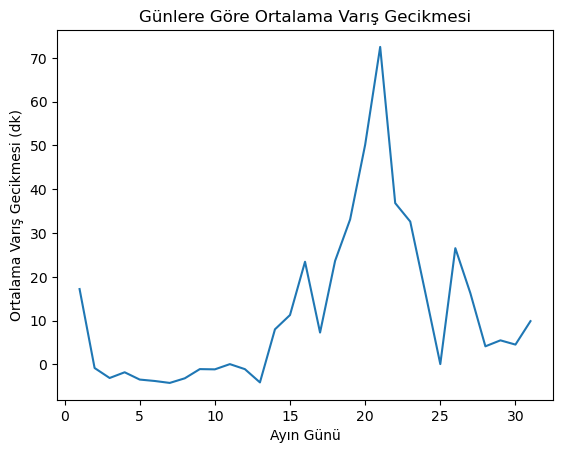

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("airline_dec_2008_50k.csv")

daily_delay = df.groupby("DayofMonth")["ArrDelay"].mean()

plt.figure()
plt.plot(daily_delay.index, daily_delay.values)
plt.xlabel("Ayın Günü")
plt.ylabel("Ortalama Varış Gecikmesi (dk)")
plt.title("Günlere Göre Ortalama Varış Gecikmesi")
plt.show()


In [3]:
df_clean = df.dropna(subset=["ArrDelay"])

df_clean["ArrDelay"] = df_clean["ArrDelay"].astype("Int64")

df_clean.to_csv("airline_dec_2008_50k_modified2.csv", index=False)

C:\Users\tatls\AppData\Local\Temp\ipykernel_35752\626463571.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean["ArrDelay"] = df_clean["ArrDelay"].astype("Int64")


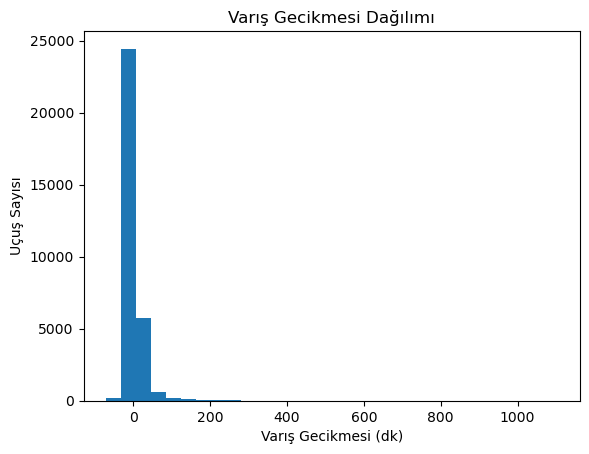

In [8]:
plt.figure()
plt.hist(df["ArrDelay"].dropna(), bins=30)
plt.xlabel("Varış Gecikmesi (dk)")
plt.ylabel("Uçuş Sayısı")
plt.title("Varış Gecikmesi Dağılımı")
plt.show()


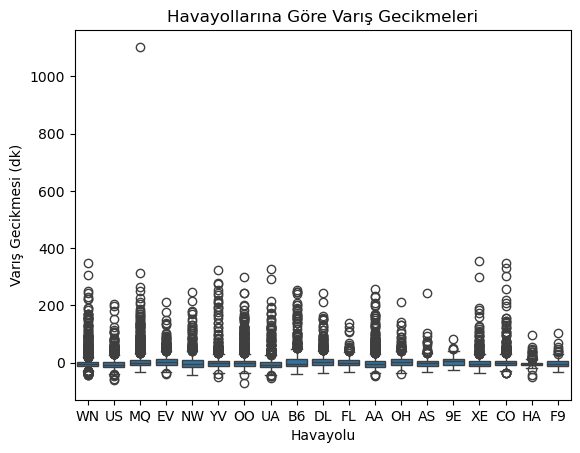

In [9]:
import seaborn as sns

plt.figure()
sns.boxplot(x="UniqueCarrier", y="ArrDelay", data=df)
plt.xlabel("Havayolu")
plt.ylabel("Varış Gecikmesi (dk)")
plt.title("Havayollarına Göre Varış Gecikmeleri")
plt.show()


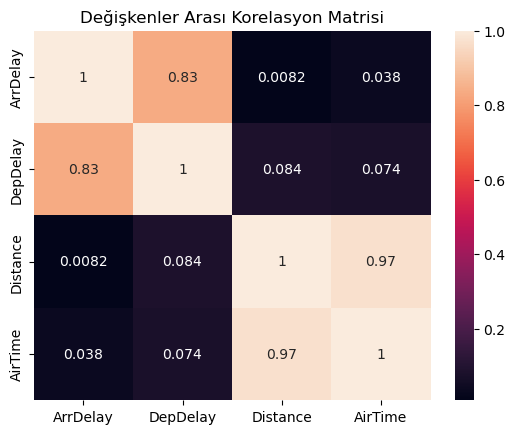

In [10]:
corr = df[["ArrDelay", "DepDelay", "Distance", "AirTime"]].corr()

plt.figure()
sns.heatmap(corr, annot=True)
plt.title("Değişkenler Arası Korelasyon Matrisi")
plt.show()


In [11]:
import plotly.express as px

top_origins = df["Origin"].value_counts().head(10).reset_index()
top_origins.columns = ["Havalimanı", "Uçuş Sayısı"]

fig = px.bar(
    top_origins,
    x="Havalimanı",
    y="Uçuş Sayısı",
    title="En Yoğun 10 Kalkış Havalimanı"
)

fig.show()
